# Lab 1 - Part 1: N-Gram Language Model

Training: `shakespeare-caesar`, `shakespeare-macbeth`  
Evaluation: `shakespeare-hamlet`

## Setup

In [2]:
import math
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd

for pkg in ["gutenberg", "punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import gutenberg, stopwords

SEED = 42
rng = np.random.default_rng(SEED)

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

TRAIN_FILES = ["shakespeare-caesar.txt", "shakespeare-macbeth.txt"]
EVAL_FILES = ["shakespeare-hamlet.txt"]

import sys
print("Python:", sys.executable)
print("Results folder:", RESULTS_DIR.resolve())
print("NLTK", nltk.__version__, "| NumPy", np.__version__)
print("Available Shakespeare files:", [f for f in gutenberg.fileids() if f.startswith("shakespeare")])

Python: /Users/omar_zydan/programming/NLP/Lab1/.venv/bin/python
Results folder: /Users/omar_zydan/programming/NLP/Lab1/results
NLTK 3.10.3 | NumPy 2.5.4
Available Shakespeare files: ['shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt']


## Preprocessing

In [3]:
BOS, EOS, UNK = "<s>", "</s>", "<UNK>"
STOPWORDS = set(stopwords.words("english"))
_NON_WORD = re.compile(r"[^a-z0-9']+")
_WORD = re.compile(r"\w+(?:'\w+)*")


def normalize_token(tok, lowercase=True, remove_punct=True):
    """Normalize a single token; returns '' if nothing is left."""
    if lowercase:
        tok = tok.lower()
    if remove_punct:
        tok = _NON_WORD.sub("", tok).strip("'")
    return tok


def tokenize(text):
    """Split text into word tokens, keeping internal apostrophes."""
    return _WORD.findall(text)


def preprocess_sentence(text_or_tokens, lowercase=True, remove_punct=True, remove_stopwords=False):
    """Raw string or token list -> list of normalized tokens."""
    tokens = tokenize(text_or_tokens) if isinstance(text_or_tokens, str) else text_or_tokens
    out = []
    for tok in tokens:
        tok = normalize_token(tok, lowercase, remove_punct)
        if not tok or (remove_stopwords and tok in STOPWORDS):
            continue
        out.append(tok)
    return out


def pad(tokens, n):
    """Add n-1 start symbols and one end symbol."""
    return [BOS] * (n - 1) + list(tokens) + [EOS]


def make_ngrams(tokens, n):
    """List of n-gram tuples from a token list."""
    return list(zip(*(tokens[i:] for i in range(n))))

## Loading the data

In [4]:
def load_corpus(fileids, remove_stopwords=False):
    """Load Gutenberg files as a list of preprocessed, non-empty sentences."""
    sentences = []
    for fid in fileids:
        for sent in nltk.sent_tokenize(gutenberg.raw(fid)):
            tokens = preprocess_sentence(sent, remove_stopwords=remove_stopwords)
            if tokens:
                sentences.append(tokens)
    return sentences


train_sents = load_corpus(TRAIN_FILES)
eval_sents = load_corpus(EVAL_FILES)

raw_sents = nltk.sent_tokenize(gutenberg.raw(TRAIN_FILES[0]))
for i in [1, 8, 40]:
    print("raw  :", " ".join(raw_sents[i].split()))
    print("clean:", " ".join(preprocess_sentence(raw_sents[i])))
    print()

raw  : Scoena Prima.
clean: scoena prima

raw  : Why Sir, a Carpenter Mur.
clean: why sir a carpenter mur

raw  : And do you now strew Flowers in his way, That comes in Triumph ouer Pompeyes blood?
clean: and do you now strew flowers in his way that comes in triumph ouer pompeyes blood



### Corpus statistics

In [5]:
def corpus_stats(sentences):
    tokens = [t for s in sentences for t in s]
    return {"sentences": len(sentences), "tokens": len(tokens), "types": len(set(tokens)),
            "avg sent len": round(len(tokens) / len(sentences), 2)}


stats = {"train (caesar + macbeth)": corpus_stats(train_sents), "eval (hamlet)": corpus_stats(eval_sents)}
for fid in TRAIN_FILES:
    stats[fid.removesuffix(".txt")] = corpus_stats(load_corpus([fid]))
display(pd.DataFrame(stats).T)

train_counts = Counter(t for s in train_sents for t in s)
eval_tokens = [t for s in eval_sents for t in s]
oov_tokens = [t for t in eval_tokens if t not in train_counts]
print(f"Hamlet OOV rate (vs. training types): {len(oov_tokens) / len(eval_tokens):.2%} of tokens, "
      f"{len(set(oov_tokens)) / len(set(eval_tokens)):.2%} of types")
print("Most common training words:", train_counts.most_common(10))
print("Most common OOV words in Hamlet:", Counter(oov_tokens).most_common(10))

,sentences,tokens,types,avg sent len
train (caesar + macbeth),3057.0,38363.0,5218.0,12.55
eval (hamlet),2355.0,29698.0,4813.0,12.61
shakespeare-caesar,1592.0,20530.0,3082.0,12.90
shakespeare-macbeth,1465.0,17833.0,3550.0,12.17


Hamlet OOV rate (vs. training types): 15.22% of tokens, 53.54% of types
Most common training words: [('the', 1228), ('and', 1172), ('i', 861), ('to', 829), ('of', 692), ('you', 593), ('that', 512), ('a', 508), ('is', 430), ('in', 424)]
Most common OOV words in Hamlet: [('ham', 337), ('hamlet', 100), ('hor', 95), ('qu', 62), ('laer', 60), ('ophe', 56), ('pol', 49), ('rosin', 43), ('horatio', 40), ('polon', 38)]


## Vocabulary
Words that appear fewer than `min_count` times in the training data are replaced by `<UNK>`.

In [6]:
class Vocabulary:
    def __init__(self, sentences, min_count=2):
        counts = Counter(t for s in sentences for t in s)
        self.min_count = min_count
        self.words = sorted(w for w, c in counts.items() if c >= min_count) + [UNK, EOS]
        self.index = {w: i for i, w in enumerate(self.words)}

    def __len__(self):
        return len(self.words)

    def __contains__(self, word):
        return word in self.index

    def map_sentence(self, tokens):
        return [t if t in self.index else UNK for t in tokens]

    def map_corpus(self, sentences):
        return [self.map_sentence(s) for s in sentences]


def unk_rate(sentences):
    tokens = [t for s in sentences for t in s]
    return tokens.count(UNK) / len(tokens)


rows = []
for mc in [1, 2, 3, 5]:
    v = Vocabulary(train_sents, min_count=mc)
    rows.append({"min_count": mc, "V": len(v),
                 "train <UNK> rate": f"{unk_rate(v.map_corpus(train_sents)):.2%}",
                 "hamlet <UNK> rate": f"{unk_rate(v.map_corpus(eval_sents)):.2%}"})
display(pd.DataFrame(rows).set_index("min_count"))

,V,train <UNK> rate,hamlet <UNK> rate
min_count,,,
1,5220,0.00%,15.22%
2,2357,7.46%,19.59%
3,1561,11.61%,22.15%
5,946,17.02%,26.15%


In [7]:
MIN_COUNT = 2
vocab = Vocabulary(train_sents, min_count=MIN_COUNT)
train_data = vocab.map_corpus(train_sents)
eval_data = vocab.map_corpus(eval_sents)

print(f"V = {len(vocab)}")
print("train:", " ".join(train_data[40]))
print("eval :", " ".join(next(s for s in eval_data[20:] if len(s) > 10)))

V = 2357
train: and do you now <UNK> flowers in his way that comes in triumph ouer pompeyes blood
eval : <UNK> <UNK> tis but our fantasie and will not let beleefe take hold of him <UNK> this <UNK> sight <UNK> seene of vs therefore i haue <UNK> him along with vs to watch the <UNK> of this night that if againe this apparition come he may <UNK> our eyes and speake to it <UNK>


## N-gram model
Laplace (add-k) smoothing:
$$P(w \mid h) = \frac{C(h, w) + k}{C(h) + kV}$$
Perplexity:
$$PP = \exp\Big(-\frac{1}{N}\sum_{i=1}^{N} \log P(w_i \mid h_i)\Big)$$

In [8]:
class NGramLM:
    def __init__(self, n, vocab, k=1.0):
        assert n >= 1 and k > 0
        self.n, self.vocab, self.k = n, vocab, k
        self.V = len(vocab)
        self.counts = defaultdict(Counter)   # context tuple -> Counter(next word -> count)
        self.context_totals = Counter()      # context tuple -> C(h)

    def _context(self, history):
        return tuple(history[-(self.n - 1):]) if self.n > 1 else ()

    def fit(self, sentences):
        for sent in sentences:
            for gram in make_ngrams(pad(self.vocab.map_sentence(sent), self.n), self.n):
                ctx, word = gram[:-1], gram[-1]
                self.counts[ctx][word] += 1
                self.context_totals[ctx] += 1
        return self

    def prob(self, word, history=()):
        ctx = self._context(list(history))
        word = word if word in self.vocab else UNK
        seen = self.counts[ctx][word] if ctx in self.counts else 0
        return (seen + self.k) / (self.context_totals[ctx] + self.k * self.V)

    def sentence_logprob(self, tokens):
        """Sum of log P over every predicted token (words + </s>), and how many there were."""
        grams = make_ngrams(pad(self.vocab.map_sentence(tokens), self.n), self.n)
        return sum(math.log(self.prob(g[-1], g[:-1])) for g in grams), len(grams)

    def perplexity(self, sentences):
        total_logprob, total_tokens = 0.0, 0
        for sent in sentences:
            lp, cnt = self.sentence_logprob(sent)
            total_logprob += lp
            total_tokens += cnt
        return math.exp(-total_logprob / total_tokens)

    def next_word_distribution(self, history=()):
        """NumPy vector P(. | h) over vocab.words."""
        ctx = self._context(list(history))
        dist = np.full(self.V, self.k)
        for word, c in self.counts.get(ctx, {}).items():
            dist[self.vocab.index[word]] += c
        return dist / dist.sum()

    def generate(self, max_len=25, seed=None, top_k=None, min_len=0, allow_unk=False, rng=None):
        rng = rng if rng is not None else np.random.default_rng()
        seed_tokens = self.vocab.map_sentence(preprocess_sentence(seed)) if seed else []
        history = [BOS] * (self.n - 1) + seed_tokens
        output = list(seed_tokens)
        for _ in range(max_len):
            p = self.next_word_distribution(history)
            if not allow_unk:
                p[self.vocab.index[UNK]] = 0.0
            if len(output) < min_len:
                p[self.vocab.index[EOS]] = 0.0
            if top_k is not None:   # keep the k best words plus any word tied with the k-th
                p[p < np.sort(p)[-top_k]] = 0.0
            p /= p.sum()
            word = self.vocab.words[rng.choice(self.V, p=p)]
            if word == EOS:
                break
            output.append(word)
            history.append(word)
        return " ".join(output)

    def __repr__(self):
        return f"NGramLM(n={self.n}, k={self.k}, V={self.V}, contexts={len(self.counts)})"

## Unigram baseline

In [9]:
unigram = NGramLM(1, vocab).fit(train_sents)
print(unigram)
print(f"Train perplexity : {unigram.perplexity(train_sents):8.2f}")
print(f"Hamlet perplexity: {unigram.perplexity(eval_sents):8.2f}")

p = unigram.next_word_distribution()
top = np.argsort(p)[::-1][:10]
display(pd.DataFrame({"word": [vocab.words[i] for i in top], "P(w)": p[top].round(4)}).set_index("word").T)

NGramLM(n=1, k=1.0, V=2357, contexts=1)
Train perplexity :   338.31
Hamlet perplexity:   186.44


word,</s>,<UNK>,the,and,i,to,of,you,that,a
P(w),0.0699,0.0654,0.0281,0.0268,0.0197,0.019,0.0158,0.0136,0.0117,0.0116


### Unigram generation

In [10]:
gen_rng = np.random.default_rng(SEED)
for i in range(3):
    print(f"{i + 1}.", unigram.generate(max_len=15, rng=gen_rng))

1. thou looke when that be
2. thinke tis brutus macb ides
3. should vnder loue euer of angry vpon septima they i


## Perplexity for n = 1 to 10

In [11]:
MAX_N = 10
models, rows = {}, []
for n in range(1, MAX_N + 1):
    m = NGramLM(n, vocab).fit(train_sents)
    models[n] = m
    eval_grams = [g for s in eval_data for g in make_ngrams(pad(s, n), n)]
    unseen_ctx = sum(g[:-1] not in m.context_totals for g in eval_grams) / len(eval_grams)
    unseen_gram = sum(m.counts[g[:-1]][g[-1]] == 0 if g[:-1] in m.counts else True for g in eval_grams) / len(eval_grams)
    rows.append({"n": n,
                 "train PP": m.perplexity(train_sents),
                 "hamlet PP": m.perplexity(eval_sents),
                 "unseen contexts": unseen_ctx if n > 1 else 0.0,
                 "unseen n-grams": unseen_gram,
                 "distinct contexts": len(m.counts)})

results = pd.DataFrame(rows).set_index("n")
results.to_csv(RESULTS_DIR / "perplexity_laplace.csv")
display(results.style.format({"train PP": "{:.1f}", "hamlet PP": "{:.1f}",
                              "unseen contexts": "{:.1%}", "unseen n-grams": "{:.1%}",
                              "distinct contexts": "{:,}"}))
best_n = results["hamlet PP"].idxmin()
print(f"Best order on Hamlet: n = {best_n} (PP = {results.loc[best_n, 'hamlet PP']:.1f})")

,train PP,hamlet PP,unseen contexts,unseen n-grams,distinct contexts
n,,,,,
1,338.3,186.4,0.0%,0.0%,1
2,512.7,483.3,0.0%,31.3%,"2,357"
3,922.5,1446.7,30.6%,70.7%,"20,840"
4,997.6,1815.7,66.9%,85.6%,"32,236"
5,1006.5,1867.1,80.0%,88.2%,"34,474"
6,1007.5,1871.7,82.2%,88.5%,"34,769"
7,1007.9,1872.3,82.4%,88.6%,"34,810"
8,1008.1,1872.8,82.5%,88.6%,"34,822"
9,1008.2,1873.1,82.5%,88.6%,"34,828"


Best order on Hamlet: n = 1 (PP = 186.4)


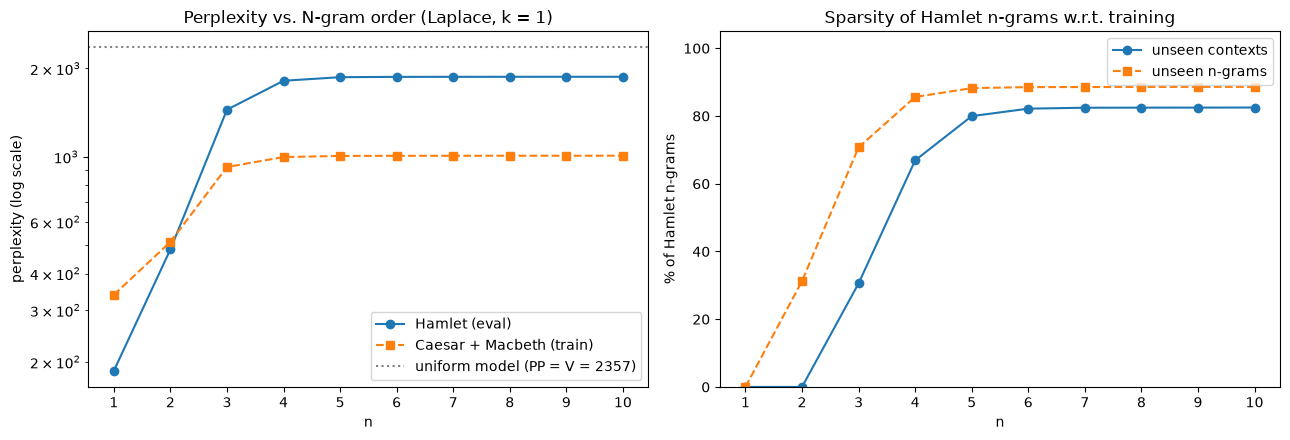

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(results.index, results["hamlet PP"], "o-", label="Hamlet (eval)")
ax.plot(results.index, results["train PP"], "s--", label="Caesar + Macbeth (train)")
ax.axhline(len(vocab), color="gray", ls=":", label=f"uniform model (PP = V = {len(vocab)})")
ax.set(xlabel="n", ylabel="perplexity (log scale)", yscale="log", title="Perplexity vs. N-gram order (Laplace, k = 1)",
       xticks=results.index)
ax.legend()

ax = axes[1]
ax.plot(results.index, results["unseen contexts"] * 100, "o-", label="unseen contexts")
ax.plot(results.index, results["unseen n-grams"] * 100, "s--", label="unseen n-grams")
ax.set(xlabel="n", ylabel="% of Hamlet n-grams", ylim=(0, 105), title="Sparsity of Hamlet n-grams w.r.t. training",
       xticks=results.index)
ax.legend()

fig.tight_layout()
fig.savefig(RESULTS_DIR / "perplexity_vs_n.png", dpi=150)
plt.show()

## Text generation

In [13]:
GEN_ORDERS = [1, 2, 3, 5, 10]
STRATEGIES = {"sample": None, "top-5": 5, "greedy": 1}

gen_rows = []
for n in GEN_ORDERS:
    gen_rng = np.random.default_rng(SEED + n)
    for name, k in STRATEGIES.items():
        for seed in [None, "my lord"]:
            text = models[n].generate(max_len=20, min_len=8, seed=seed, top_k=k, rng=gen_rng)
            gen_rows.append({"n": n, "strategy": name, "seed": seed or "-", "text": text})

generations = pd.DataFrame(gen_rows)
generations.to_csv(RESULTS_DIR / "generations.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(generations.style.hide(axis="index")
            .set_properties(subset=["text"], **{"text-align": "left"}))

n,strategy,seed,text
1,sample,-,ranke and actus three of done that fighting lad macb
1,sample,my lord,my lord vp for for is a ground
1,top-5,-,to of of to the to to and and
1,top-5,my lord,my lord and i i of and of to and the to the the the and
1,greedy,-,the the the the the the the the
1,greedy,my lord,my lord the the the the the the
2,sample,-,but ere hoboyes window conference terror confess'd gallant read peece when horses warlike vnnaturall satisfie alas speed triumph may'st dayes
2,sample,my lord,my lord country takes birnane mooue deed fiery woe eyes reigne sir fashion cleane slay kinsman farwell desire worth practice matters but
2,top-5,-,what i will you are you to the will come to me to the king
2,top-5,my lord,my lord macb euerlasting defend foorth now is no more


## Add-k smoothing

In [14]:
K_VALUES = [1, 0.1, 0.01, 0.001]
addk_rows = []
for k in K_VALUES:
    for n in range(1, MAX_N + 1):
        m = models[n] if k == 1 else NGramLM(n, vocab, k=k).fit(train_sents)
        addk_rows.append({"k": k, "n": n, "train PP": m.perplexity(train_sents), "hamlet PP": m.perplexity(eval_sents)})

addk = pd.DataFrame(addk_rows)
addk.to_csv(RESULTS_DIR / "perplexity_add_k.csv", index=False)
display(addk.pivot(index="n", columns="k", values="hamlet PP").round(1)
        .rename(columns=lambda k: f"Hamlet PP (k={k})"))

best = addk.loc[addk["hamlet PP"].idxmin()]
print(f"Best overall: k = {best.k}, n = {int(best.n)}, Hamlet PP = {best['hamlet PP']:.1f}")

k,Hamlet PP (k=0.001),Hamlet PP (k=0.01),Hamlet PP (k=0.1),Hamlet PP (k=1.0)
n,,,,
1,182.8,182.9,183.1,186.4
2,374.9,246.1,258.5,483.3
3,1089.4,825.8,983.2,1446.7
4,1568.9,1441.1,1561.6,1815.7
5,1674.5,1602.6,1680.4,1867.1
6,1686.3,1622.2,1693.0,1871.7
7,1687.5,1624.3,1694.4,1872.3
8,1689.4,1625.8,1695.4,1872.8
9,1692.1,1627.6,1696.4,1873.1


Best overall: k = 0.001, n = 1, Hamlet PP = 182.8


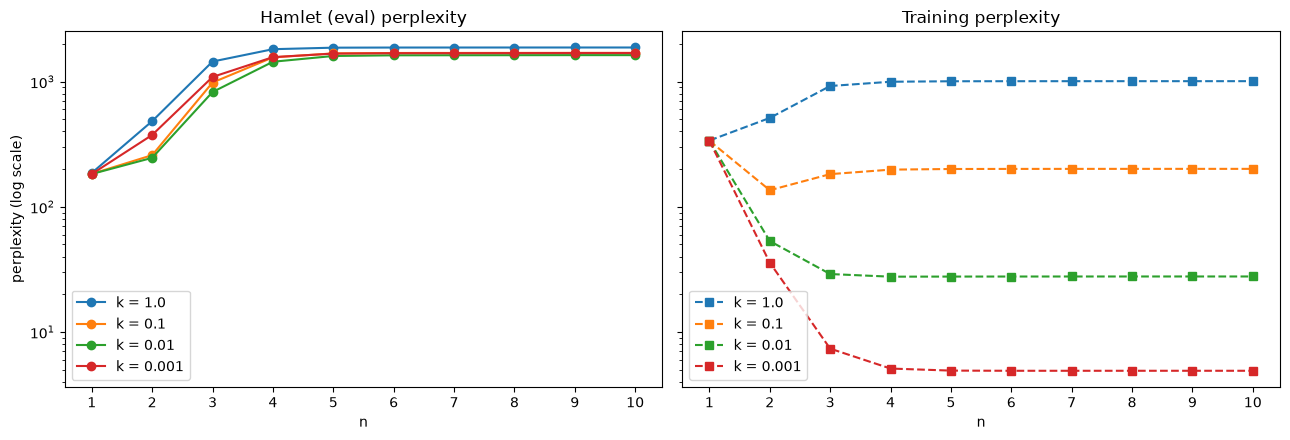

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for k, grp in addk.groupby("k", sort=False):
    axes[0].plot(grp.n, grp["hamlet PP"], "o-", label=f"k = {k}")
    axes[1].plot(grp.n, grp["train PP"], "s--", label=f"k = {k}")
axes[0].set(title="Hamlet (eval) perplexity", xlabel="n", ylabel="perplexity (log scale)", yscale="log")
axes[1].set(title="Training perplexity", xlabel="n", yscale="log")
for ax in axes:
    ax.set_xticks(range(1, MAX_N + 1))
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "perplexity_add_k.png", dpi=150)
plt.show()

In [16]:
best_k = addk[addk.n == 2].set_index("k")["hamlet PP"].idxmin()
print(f"k = {best_k}:")
for n in [2, 3]:
    m = NGramLM(n, vocab, k=best_k).fit(train_sents)
    r = np.random.default_rng(SEED + n)
    for _ in range(2):
        print(f"  n={n}:", m.generate(max_len=20, rng=r))

k = 0.01:
  n=2: but go lose will come to countenance groomes schoole pluckt wearie iudgement wisedom wholsome require a summers troopes macb
  n=2: come to beard motiues dispaire forrest with her she saw hedge cobl sutors look gainst deere wiues promis'd mother but
  n=3: messa ruines silent stayes maiesty smoake speake one hold quarta pine sweetly sea memory why leade stay there proceeded attaine
  n=3: and come shame aside rise houre guest colour bright captiuitie smell countenance runne robes matter whilst haires appar lost decius


## Stopword removal

In [17]:
train_ns = load_corpus(TRAIN_FILES, remove_stopwords=True)
eval_ns = load_corpus(EVAL_FILES, remove_stopwords=True)
vocab_ns = Vocabulary(train_ns, min_count=MIN_COUNT)
print(f"Without stopwords: {corpus_stats(train_ns)['tokens']:,} train tokens (was {corpus_stats(train_sents)['tokens']:,}), "
      f"V = {len(vocab_ns)} (was {len(vocab)})")

sw_rows = []
for n in [1, 2, 3, 5, 10]:
    for label, (tr, ev, voc) in {"kept": (train_sents, eval_sents, vocab),
                                 "removed": (train_ns, eval_ns, vocab_ns)}.items():
        for k in [1, 0.01]:
            m = NGramLM(n, voc, k=k).fit(tr)
            sw_rows.append({"n": n, "stopwords": label, "k": k, "hamlet PP": m.perplexity(ev)})
sw = pd.DataFrame(sw_rows).pivot(index="n", columns=["stopwords", "k"], values="hamlet PP").round(1)
display(sw)

m_ns = NGramLM(2, vocab_ns, k=0.01).fit(train_ns)
r = np.random.default_rng(SEED)
print("Bigram text without stopwords (k = 0.01):")
for _ in range(2):
    print("  ", m_ns.generate(max_len=15, min_len=6, rng=r))

Without stopwords: 21,300 train tokens (was 38,363), V = 2254 (was 2357)


stopwords    kept         removed        
k            1.00    0.01    1.00    0.01
n                                        
1           186.4   182.9   145.1   140.8
2           483.3   246.1   486.3   288.8
3          1446.7   825.8  1163.4   847.7
5          1867.1  1602.6  1511.2  1282.1
10         1873.1  1627.6  1534.0  1331.0

Bigram text without stopwords (k = 0.01):
   send hither spoken ride came wil smiles sort chanc'd hony heauy valiant offered take leaue
   dwell makes bleeding stabb'd patience seize haunt willing thunders spring desir'd ioyfull awak'd comes pine
